# Classification de tumeurs du sein

**Objectif :** prédire si une tumeur du sein est maligne ou bénigne à partir de mesures réalisées sur des images de cellules.

**Données :** dataset *Breast Cancer Wisconsin* (intégré à scikit-learn), 569 tumeurs.

**Variables d'entrée (features) :** 30 mesures numériques : 10 caractéristiques des cellules (rayon, texture, périmètre, surface…), chacune calculée en moyenne (`mean`), écart-type (`error`) et valeur extrême (`worst`).

**Cible (label) :** `target` → 0 = maligne, 1 = bénigne.

**Type de problème :** classification supervisée binaire (2 classes).

In [29]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

## 2. Répartition des classes

Le dataset contient 357 tumeurs bénignes (62,7 %) et 212 malignes (37,3 %) : les classes sont **déséquilibrées**.
Un modèle qui prédirait toujours « bénigne » obtiendrait déjà 62,7 % d'accuracy tout en ratant **100 % des cancers**. L'accuracy seule n'est donc pas suffisante : on suivra en priorité le **rappel de la classe maligne** (part des cancers réellement détectés), car un faux négatif (cancer non détecté) est bien plus grave qu'une fausse alerte.

In [7]:
data = load_breast_cancer(as_frame=True) 
df = data.frame
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## 3. Nettoyage

In [8]:
df.shape

(569, 31)

In [9]:
data.target_names

array(['malignant', 'benign'], dtype='<U9')

In [10]:
df["target"].value_counts()

target
1    357
0    212
Name: count, dtype: int64

In [11]:
df.duplicated().sum()


np.int64(0)

In [12]:
df.isnull().sum().sum()

np.int64(0)

### 4.1 Échelles des variables

Les variables ont des ordres de grandeur très différents : `mean area` va de 143 à 2 501, alors que `mean smoothness` reste entre 0,05 et 0,16.
Pour les modèles basés sur des distances (KNN, SVM), `mean area` dominerait le calcul et `mean smoothness` serait presque ignorée, même si elle est utile. Une mise à l'échelle avec `StandardScaler` sera donc indispensable, intégrée dans un pipeline.

In [13]:
df.describe().round(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,...,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000
mean,14.127,19.290,91.969,654.889,0.096,0.104,0.089,0.049,0.181,0.063,...,25.677,107.261,880.583,0.132,0.254,0.272,0.115,0.290,0.084,0.627
std,3.524,4.301,24.299,351.914,0.014,0.053,0.080,0.039,0.027,0.007,...,6.146,33.603,569.357,0.023,0.157,0.209,0.066,0.062,0.018,0.484
min,6.981,9.710,43.790,143.500,0.053,0.019,0.000,0.000,0.106,0.050,...,12.020,50.410,185.200,0.071,0.027,0.000,0.000,0.156,0.055,0.000
25%,11.700,16.170,75.170,420.300,0.086,0.065,0.030,0.020,0.162,0.058,...,21.080,84.110,515.300,0.117,0.147,0.114,0.065,0.250,0.071,0.000
50%,13.370,18.840,86.240,551.100,0.096,0.093,0.062,0.034,0.179,0.062,...,25.410,97.660,686.500,0.131,0.212,0.227,0.100,0.282,0.080,1.000
75%,15.780,21.800,104.100,782.700,0.105,0.130,0.131,0.074,0.196,0.066,...,29.720,125.400,1084.000,0.146,0.339,0.383,0.161,0.318,0.092,1.000
max,28.110,39.280,188.500,2501.000,0.163,0.345,0.427,0.201,0.304,0.097,...,49.540,251.200,4254.000,0.223,1.058,1.252,0.291,0.664,0.208,1.000


### 4.2 Variables les plus liées au diagnostic

Les variables les plus corrélées à la cible sont `worst concave points`, `worst perimeter`, `mean concave points`, `worst radius` et `mean perimeter` (corrélations d'environ −0,78).
Le signe négatif indique que plus ces valeurs sont élevées, plus `target` tend vers 0, c'est-à-dire vers une tumeur **maligne** : les cellules malignes sont plus grandes et ont un contour plus irrégulier (plus de creux).


In [14]:
df.corr()["target"].sort_values()

worst concave points      -0.793566
worst perimeter           -0.782914
mean concave points       -0.776614
worst radius              -0.776454
mean perimeter            -0.742636
worst area                -0.733825
mean radius               -0.730029
mean area                 -0.708984
mean concavity            -0.696360
worst concavity           -0.659610
mean compactness          -0.596534
worst compactness         -0.590998
radius error              -0.567134
perimeter error           -0.556141
area error                -0.548236
worst texture             -0.456903
worst smoothness          -0.421465
worst symmetry            -0.416294
mean texture              -0.415185
concave points error      -0.408042
mean smoothness           -0.358560
mean symmetry             -0.330499
worst fractal dimension   -0.323872
compactness error         -0.292999
concavity error           -0.253730
fractal dimension error   -0.077972
symmetry error             0.006522
texture error              0

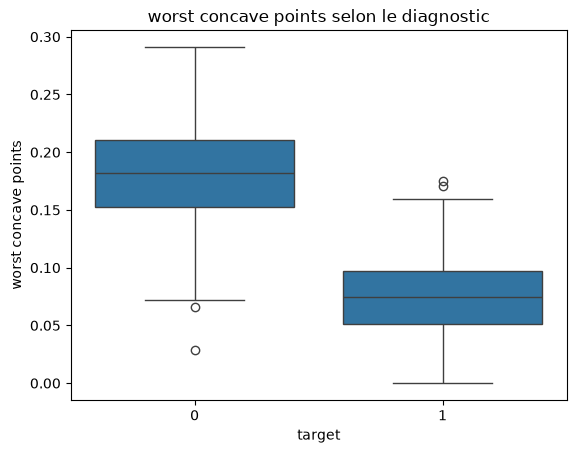

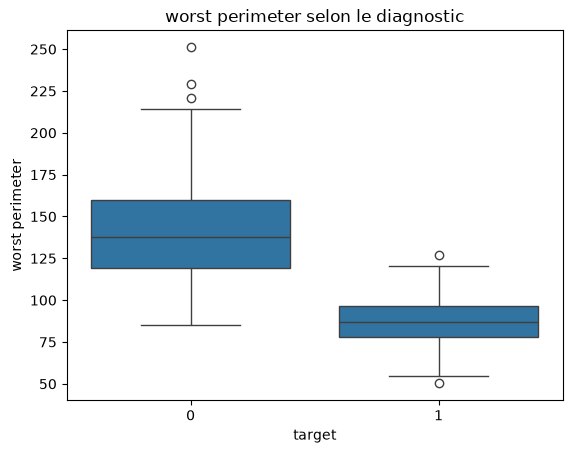

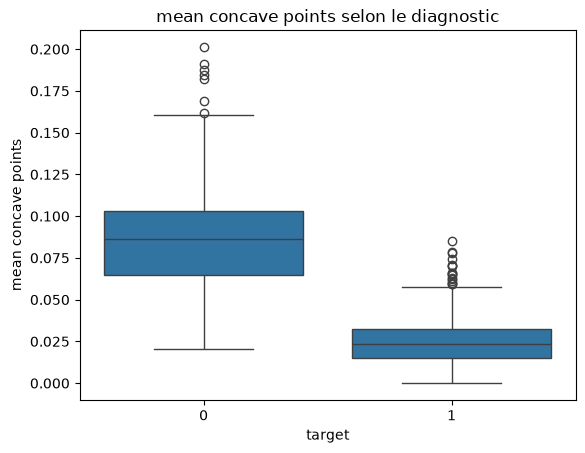

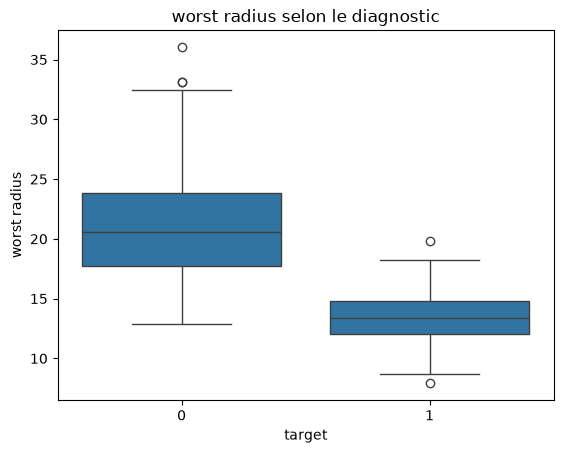

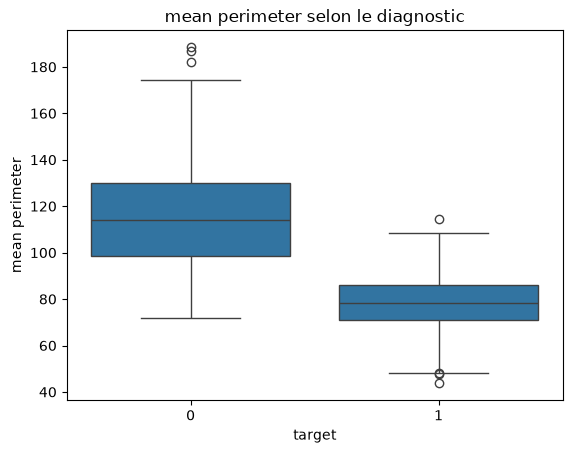

In [19]:
liste = ["worst concave points", "worst perimeter", "mean concave points", "worst radius", "mean perimeter"]        # 1. les noms des colonnes à tracer

for col in liste:                    # 2. à chaque tour, col = un nom de la liste
    sns.boxplot(data=df, x="target", y=col)   # 3. le graphique
    plt.title(f"{col} selon le diagnostic")                # 4. le titre
    plt.show()                       # 5. afficher

### 4.3 Boxplots des 5 variables les plus liées au diagnostic

Pour les 5 variables, les tumeurs malignes (0) ont des valeurs nettement plus élevées que les bénignes (1) : cellules plus grandes et contour plus irrégulier.
Aucune variable ne suffit cependant à elle seule : les moustaches des deux classes se chevauchent, donc le modèle devra combiner plusieurs variables, et des erreurs restent possibles dans cette zone de chevauchement.

In [22]:
corr = df[liste].corr()

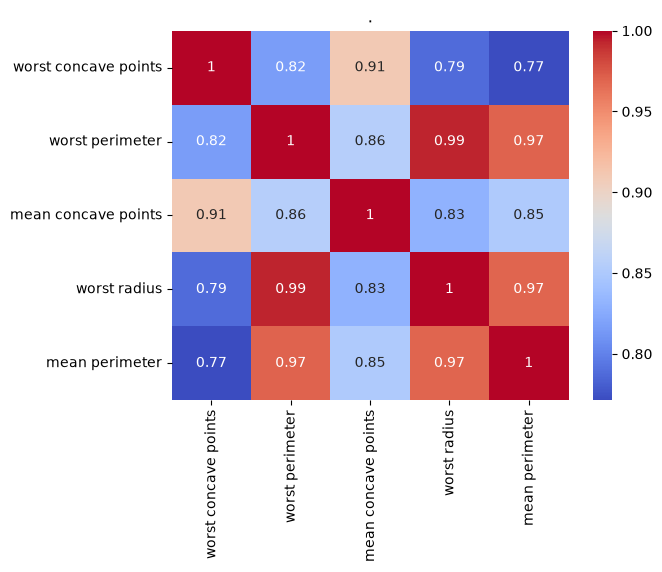

In [24]:
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title(".")
plt.show()



### 4.4 Redondance entre variables

`worst perimeter`, `worst radius` et `mean perimeter` sont quasiment identiques (corrélations de 0,97 à 0,99) : elles mesurent toutes la **taille** de la cellule (le périmètre étant proportionnel au rayon). Les variables `concave points`, moins corrélées aux autres (~0,8), apportent une information complémentaire sur la **forme** du contour.
Cette redondance (multicolinéarité) n'empêche pas les modèles de fonctionner, mais elle rend l'interprétation de certains modèles, comme la régression logistique, plus délicate.

## 5. Préparation des données

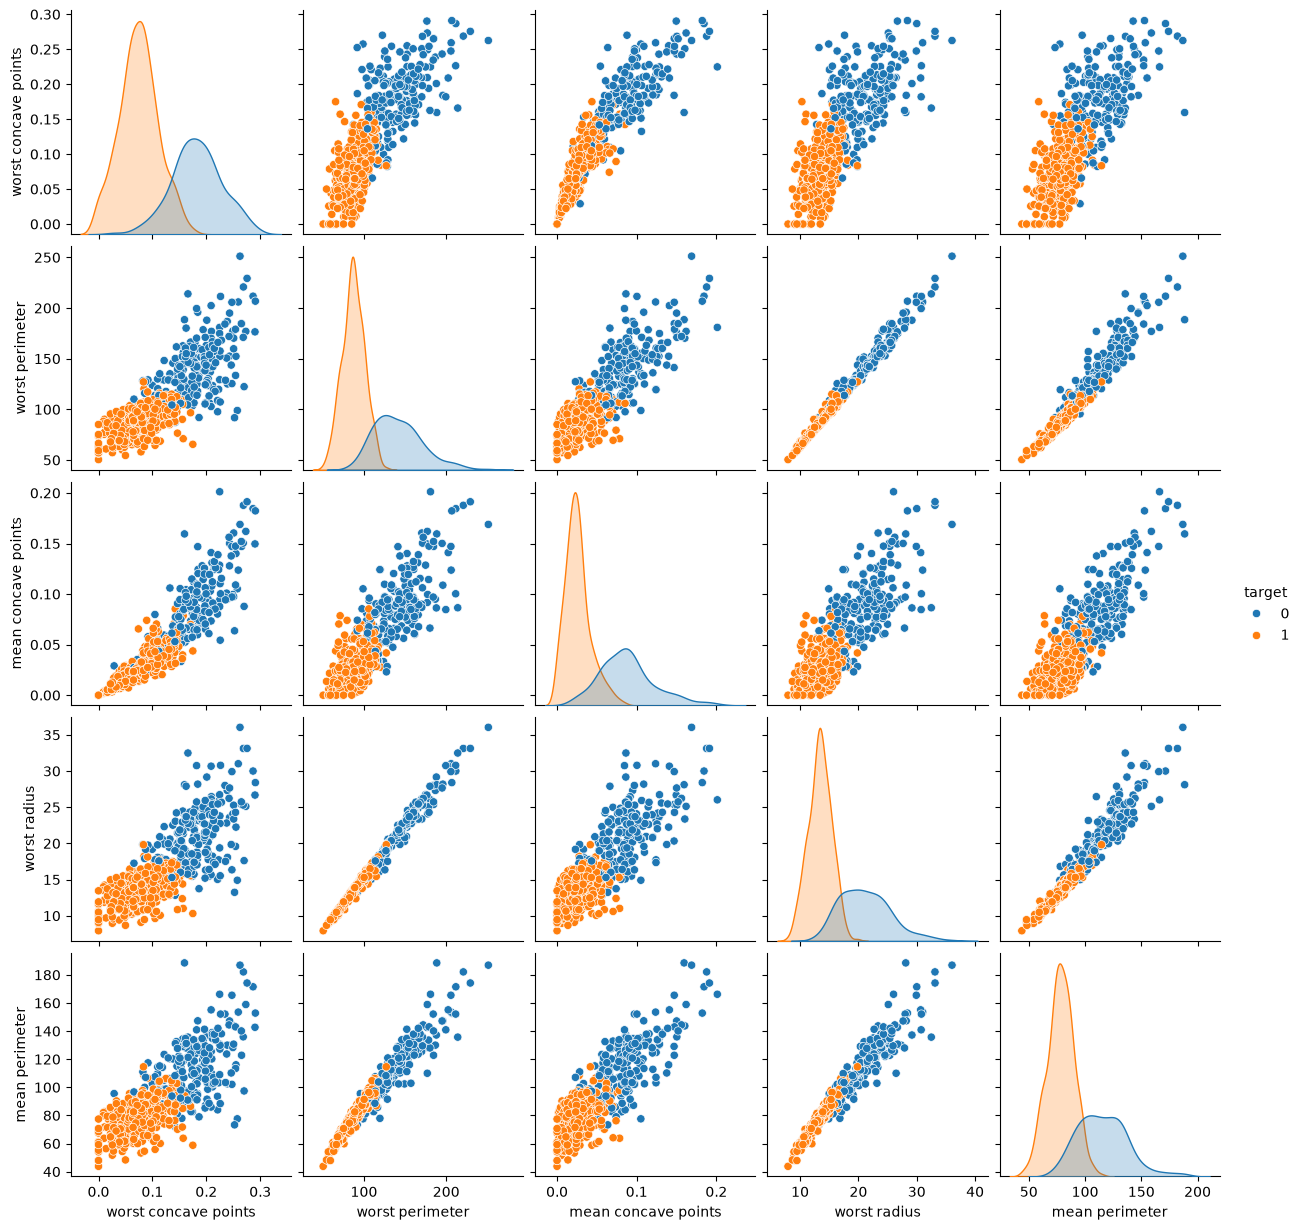

In [26]:
sns.pairplot(df, vars=liste, hue="target")

## 5. Préparation des données

Les 30 mesures forment les variables d'entrée (`X`) et la colonne `target` la cible (`y`). Les données sont séparées en 80 % d'entraînement (455 tumeurs) et 20 % de test (114 tumeurs), ce dernier n'étant utilisé qu'à l'évaluation finale.
Comme les classes sont déséquilibrées (~63 % bénignes / 37 % malignes), le split est **stratifié** : les deux jeux conservent la même proportion de tumeurs malignes (37,4 % en train, 36,8 % en test), ce qui garantit une évaluation représentative.

In [27]:
X = df.drop(columns=["target"])
y = df["target"]

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [31]:
print(X_train.shape)
print(X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(455, 30)
(114, 30)
target
1    0.626374
0    0.373626
Name: proportion, dtype: float64
target
1    0.631579
0    0.368421
Name: proportion, dtype: float64
